# Lecture 8 — Reading and Writing Files (Python)

# Reading and Writing Files

Python performs file operations in the following order:

- Open the file (`open()`)
- Read from and/or write to the file (`read()`, `write()`)
- Close the file (`close()`)

## Opening a File

Python has a built-in `open()` function for opening a file:

```python
f = open([path]filename[, mode])
```

This function returns a file object.

```python
f = open('C:/my_python/test.txt', 'r')
```

You can specify the file opening mode (`mode`):

- **`r` (read)** – opens the file for reading. If the specified file does not exist, an error message `NoDataFound` is displayed.
- **`w` (write)** – opens the file for writing. Creates a new file if it does not exist, or deletes the file contents if it exists (overwrite).
- **`a` (append)** – opens the file for appending without deleting its contents. Creates a new file if it does not exist.
- **`r+` (read & write)** – opens the file for reading and writing. If the specified file does not exist, an error message `NoDataFound` is displayed. Overwrites the file contents at the positions where new text is written.
- **`w+` (write & read)** – opens the file for writing and reading. If the file does not exist, `NoDataFound` is not displayed; instead, a new file is created. If the file exists, its contents are overwritten.
- **`a+` (append & read)** – opens the file for appending and reading. Creates a new file if it does not exist. If the file exists, its contents are appended.
- **`x` (exclusive)** – creates a new file. If such a file already exists, a `FileExistsError` is displayed.

If no opening mode is specified, the file is opened for reading (`r`).

You can also specify whether to open the file in text or binary mode:

- **`t` (text)** – text mode.
- **`b` (binary)** – binary mode.

A binary file is any type of file that is not a text file.

---

## Closing a File

After finishing operations with a file, it is recommended to close it:

```python
f.close()
```

---

## File Object Properties

- `f.name` – file name.
- `f.mode` – file opening mode.
- `f.closed` – returns `True` if the file is closed.
- `f.readable()` – returns `True` if the file is opened for reading.
- `f.writable()` – returns `True` if the file is opened for writing or appending.

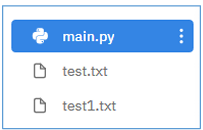

In [1]:
f = open('test.txt', 'r')
print('File name:', f.name)
print('Open mode:', f.mode)
print('Is file readable:', f.readable())
print('Is file writable:', f.writable())

f.close()
print('Is file closed:', f.closed)

File name: test.txt
,Open mode: r
,Is file readable: True
,Is file writable: False
,Is file closed: True


The next two cells just demonstrate the `open()` syntax for two more modes and produce no visible output on their own. The second one is a deliberate error: `'x'` mode requires the file to *not* already exist, but `test.txt` was just created above, so it raises `FileExistsError`:

In [23]:
f = open('test.txt', 'a+')

In [24]:
f = open('test.txt', 'x')

<class 'FileExistsError'>: [Errno 20] File exists: 'test.txt'

## Writing Text to a File

* `write(str)` – writes a string to a file.
* `writelines(list of str)` – writes a list of strings to a file.


In [25]:
f = open('test.txt', 'w')
f.write('Line 1\n')
f.write('Line 2\n')
f.write('Line 3\n')
f.close()

In [26]:
f = open('test.txt', 'a') 
L = ['Line 4\n','Line 5\n','Line 6\n'] 
f.writelines(L) 
f.close() 

In [5]:
name = input('Enter file name: ')
f = open(name, 'w')

while True:
    data = input('Enter data to write: ')
    f.write(data + '\n')

    ans = input('\nDo you want to continue? Y/N: ')
    if ans.lower() == 'n':
        break

f.close()

Enter file name:  test.txt
,Enter data to write:   
,
,Do you want to continue? Y/N:  N


## Reading Text from a File

- `read()` – reads the entire text.
- `read(n)` – reads `n` characters, including `'\n'`.
- `readline()` – reads one line.
- `readlines()` – reads all lines into a list.

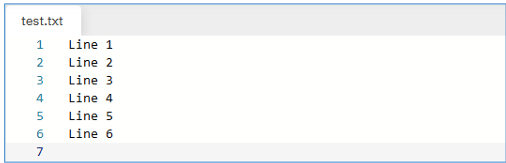

In [1]:
f = open('test.txt', 'r')
data = f.read()
print(data)
f.close()

Line 1
,Line 2
,Line 3
,Line 4
,Line 5
,Line 6
,


In [28]:
f = open('test.txt', 'r')
data = f.read(11)
print(data)
f.close()

Line 1
,Line


In [29]:
f = open('test.txt', 'r')

line1 = f.readline()
print(line1, end='')

line2 = f.readline()
print(line2, end='')

line3 = f.readline()
print(line3, end='')

f.close()

Line 1
,Line 2
,Line 3


In [30]:
f = open('test.txt', 'r')

for i in range(4):
    print(f.readline(), end='')

f.close()

Line 1
,Line 2
,Line 3
,Line 4


In [31]:
f = open('test.txt', 'r')
L = f.readlines()
f.close()

print(L)

['Line 1\n', 'Line 2\n', 'Line 3\n', 'Line 4\n', 'Line 5\n', 'Line 6\n']


In [12]:
f = open('test.txt', 'r')

print(f.read(3))        # Lin
print(f.readline())     # e 1 and an empty line ('\n')
print(f.read(4))        # Line
print(f.readline())     # 2 and an empty line ('\n')
print(f.read())         # all remaining lines

f.close()

 
,L
,ine 4
,
,Line
, 5
,
,Line 6
,


A file object is an iterator, so its contents can be displayed using the `__next__()` method or with a `for` loop.

In [13]:
f = open('test.txt', 'r')

print(f.__next__(), end='')
print(f.__next__(), end='')

f.close()

 
,Line 4


In [14]:
f = open('test.txt', 'r')

for line in f:
    print(line, end='')

f.close()

 
,Line 4
,Line 5
,Line 6


Data can be read from one file and written to another.

In [15]:
f = open('test.txt', 'r')
f1 = open('test1.txt', 'w')

lines = f.read()
f1.write(lines.upper())

f.close()
f1.close()

## The `with` Statement

The `with` statement is used when opening a file. All file operations are performed inside the `with` block (the lines are indented). When the block ends, the file is closed automatically.

In [16]:
with open('test1.txt', 'r') as f:
    data = f.read()
    print(data)
    print(f.closed)

print(f.closed)

 
,LINE 4
,LINE 5
,LINE 6
,
,False
,True


In [17]:
# The program copies all lines except the second one (LINE 2)
# from test1.txt to lines.txt.

with open('test1.txt', 'r') as f:
    lines = f.readlines()  # create a list of lines (list of strings)

count = len(lines)

with open('lines.txt', 'w') as f:
    for line in lines:
        if count != 5:
            f.write(line)
        count -= 1


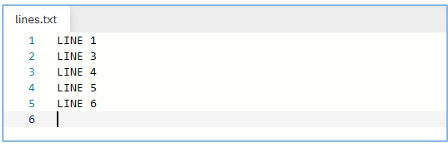

A list can be read from a file using a `with` statement:

**data.txt**
```
1 2 3
4 5 6
7 8 9
```

The four cells below show different ways to read the same `data.txt` into Python — as one long string split into tokens, as a list of raw lines, as a list of cleaned-up lines, and as a list of lists (each line split into its own tokens):

In [ ]:
with open('data.txt','r') as f:
    L = (f.read()).split()
print(L)

['1', '2', '3', '4', '5', '6', '7', '8', '9']


In [ ]:
with open('data.txt','r') as f:
    L = f.readlines()
print(L)

['1 2 3\n', '4 5 6\n', '7 8 9\n']


In [ ]:
L = []
with open('data.txt','r') as f:
    for line in f:
        L.append(line.strip()) # see append() method in "List methods"
print(L)

['1 2 3', '4 5 6', '7 8 9']


In [ ]:
L = []
with open('data.txt','r') as f:
    for line in f:
        L.append((line.strip()).split())
print(L)

[['1', '2', '3'], ['4', '5', '6'], ['7', '8', '9']]


## `tell()` and `seek()` Methods

The `tell()` method returns the cursor position counted from the beginning of the file.

The position (index) of the first character in a file is zero.

In [18]:
with open('test1.txt', 'r') as f:
    print(f.tell())      # 0
    print(f.read(3))     # LIN
    print(f.tell())      # 3
    print(f.read(3))     # E 1
    print(f.tell())      # 6
    print(f.read(1))     # empty line ('\n')
    print(f.tell())      # 7
    print(f.read(7))     # LINE 2 and an empty line ('\n')
    print(f.tell())      # 14

0
, 
,L
,3
,INE
,6
, 
,7
,4
,LINE 
,14


The `seek()` method moves the cursor to the specified position counted from the beginning of the file.

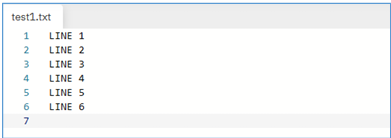

In [2]:
with open('test1.txt', 'r') as f:
    print(f.read(6))     # LINE 1
    print(f.tell())      # 6

    f.seek(14)

    print(f.read())

LINE 1
,6
,LINE 3
,LINE 4
,LINE 5
,LINE 6
,


|  Position | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |  9 | 10 | 11 | 12 | 13 | 14 | 15 | 16 | 17 | 18 | 19 | 20 | 21 | 22 | 23 |
| --------: | - | - | - | - | - | - | - | - | - | -: | -: | -: | -: | -: | -: | -: | -: | -: | -: | -: | -: | -: | -: | -: |
| Character | T | h | e | ␠ | f | o | x | ␠ | j |  u |  m |  p |  s |  ␠ |  o |  v |  e |  r |  ␠ |  a |  ␠ |  d |  o |  g |


In [20]:
f = open('text.txt', 'w')
f.write('The fox jumps over a dog\n')
f.close()

with open('text.txt', 'r+') as f:
    data = f.read()
    print(data, end='')

    f.seek(21)
    f.write('cat')

    print(f.tell())  # 24

    f.seek(0)
    data = f.read()
    print(data)

The fox jumps over a dog
,24
,The fox jumps over a cat
,


In [6]:
# The program prints the line number, the number of words,
# and the number of characters in the line.
# l_nr – line number
# w_count – number of words in the line
# s_count – number of characters (including '\n') in the line

l_nr = 0

with open('names.txt', 'r') as f:
    for line in f:
        l_nr += 1
        w_count = len(line.split())
        s_count = len(line)
        print('{}: words - {}, characters - {}'.format(l_nr, w_count, s_count))

1: words - 2, characters - 20
,2: words - 3, characters - 19
,3: words - 3, characters - 19
,4: words - 2, characters - 15
,5: words - 1, characters - 19


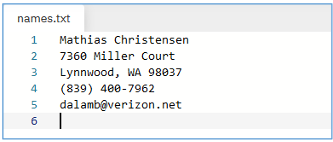

In [7]:
with open('names.txt', 'r') as f: 
  f.seek(39) 
  print(f.read())

Lynnwood, WA 98037
,(839) 400-7962
,dalamb@verizon.net 


## `os.path.isfile()` Method

The `os.path.isfile([path]filename)` method from the `os` module returns `True` if the file `filename` exists and `False` if it does not exist.

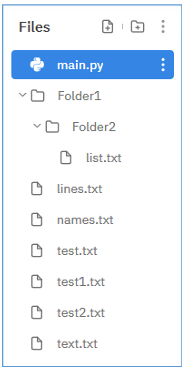

In [3]:
import os

print(os.path.isfile('lines.txt'))                # True
print(os.path.isfile('list.txt'))                 # False
print(os.path.isfile('Folder1/Folder2/list.txt')) # True

if os.path.isfile('test.txt'):
    print('The file exists')
else:
    print('The file does not exist')

True
,False
,False
,The file exists
